# Qismet on Fashion-MNIST: grouped pruning and retrainability

**An executed, fixed-protocol experiment; no quantum-advantage assumption.**

The classifier receives **784 grayscale pixel values** (a flattened 28×28 clothing image)
and predicts one of **10 clothing classes**. The supported model is 784 → 16 ReLU → 10 logits.
Eight binary pruning variables each control a fixed adjacent pair of hidden neurons:
groups `(0,1)`, `(2,3)`, …, `(14,15)`. Retaining four groups removes 50% of hidden neurons;
retaining two removes 75%. Both searches use **eight simulated qubits**.

We use 5,000 stratified training examples and 1,000 separate validation examples from the
official training set, plus all 10,000 official test examples. Input pixels are divided by
255. Five initialization seeds share one fixed data split. Every dense and sparse model
receives 20 epochs of Adam, learning rate 0.003, batches of 256, with paired epoch shuffles.

The original initialization is saved before dense training. Pruning slices hidden rows,
biases and output columns, resets the surviving weights to that checkpoint, and uses a
fresh optimizer. Exact restoration and structural equivalence are asserted.


## Execution and reproducibility

This notebook defaults to **reading saved experimental outputs**. Its displayed analyses
are executed, while training is performed by `fashion_experiment.py`. Set `RUN_EXPERIMENT`
to `True` to invoke the runner before analysis; it resumes seeds with complete checkpoints.
Changing the declared protocol requires a separate output folder, so completed results
cannot silently be reused under different settings.

Keep this folder beside `qaoa_utils.py` and install the parent `requirements.txt`.
Run `python fashion_experiment.py` to perform training and `python build_report.py` to rebuild
this notebook and HTML report. All source code and per-seed evidence remain available.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t
from IPython.display import display, Markdown, Image

BASE = Path('.')
RUN_EXPERIMENT = False
if RUN_EXPERIMENT:
    import fashion_experiment as f
    f.run_all()
config = json.loads((BASE/'protocol.json').read_text())
comparison = pd.read_csv(BASE/'results/comparison.csv', dtype={'states':str})
curves = pd.read_csv(BASE/'results/learning_curves.csv')
audit = pd.read_csv(BASE/'results/surrogate_audit.csv')
qaoa = pd.read_csv(BASE/'results/qaoa_diagnostics.csv', dtype={'qaoa_mask':str,'exact_mask':str})
assert len(comparison)==70
assert comparison.groupby(['pruning','method']).size().eq(5).all()
assert set(comparison.seed)==set(config['seeds'])
assert len(audit)==20 and len(qaoa)==10
assert comparison.test_accuracy.between(0,1).all()
assert qaoa.ising_max_error.max()<1e-8
for seed in config['seeds']:
    labels=pd.read_csv(BASE/'results'/f'seed_{seed}'/'labels.csv',dtype={'mask':str})
    fit=labels[labels.split=='fit']
    masks=np.array([list(map(int,m)) for m in fit['mask']])
    design=np.column_stack([np.ones(len(masks)),masks]+[masks[:,i]*masks[:,j] for i in range(8) for j in range(i+1,8)])
    assert np.linalg.matrix_rank(design)==37
print(json.dumps(config,indent=2))
print('Verified five seeds, two pruning budgets, seven methods, rank-37 fitting designs and Ising energy checks.')


{
  "dataset_seed": 2026,
  "train_size": 5000,
  "validation_size": 1000,
  "test_size": 10000,
  "seeds": [
    11,
    22,
    33,
    44,
    55
  ],
  "hidden": 16,
  "groups": 8,
  "group_size": 2,
  "keep_groups": [
    4,
    2
  ],
  "epochs": 20,
  "batch_size": 256,
  "lr": 0.003,
  "fit_masks": 128,
  "audit_masks": 49,
  "shots": 32,
  "qaoa_reps": 2,
  "qaoa_restarts": 3,
  "qaoa_maxiter": 120,
  "random_masks": 10,
  "ridge_alphas": [
    0.0001,
    0.01,
    0.1,
    1.0,
    10.0
  ]
}
Verified five seeds, two pruning budgets, seven methods, rank-37 fitting designs and Ising energy checks.


## Actual inputs: clothing images

The grid contains one example per class from the exact 5,000-image training subset used
in this experiment. Unlike the original Two Moons task, these are real grayscale images.


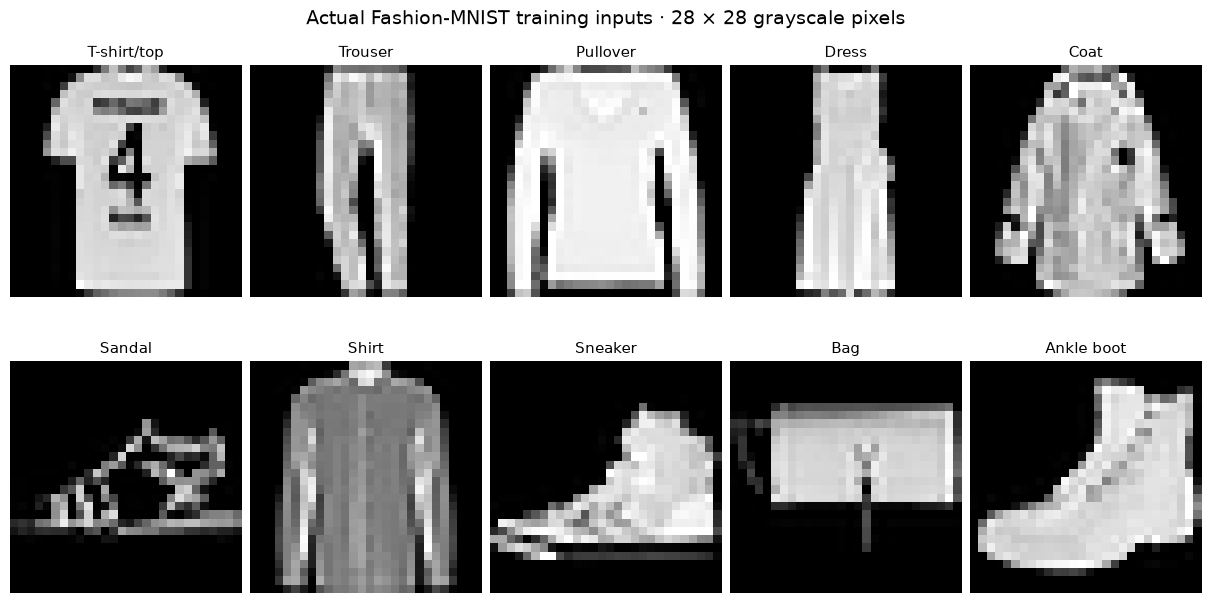

In [2]:
arrays=np.load(BASE/'dataset_subset.npz')
class_names=['T-shirt/top','Trouser','Pullover','Dress','Coat','Sandal','Shirt','Sneaker','Bag','Ankle boot']
assert arrays['train_images'].shape==(5000,28,28)
assert arrays['val_images'].shape==(1000,28,28)
assert arrays['test_images'].shape==(10000,28,28)
fig,axs=plt.subplots(2,5,figsize=(12,6.2),layout='constrained')
for label,ax in enumerate(axs.flat):
    idx=np.flatnonzero(arrays['train_labels']==label)[0]
    ax.imshow(arrays['train_images'][idx],cmap='gray',vmin=0,vmax=255)
    ax.set_title(class_names[label],fontsize=11)
    ax.axis('off')
fig.suptitle('Actual Fashion-MNIST training inputs · 28 × 28 grayscale pixels',fontsize=14)
fig.savefig(BASE/'fashion_examples.png',dpi=160,bbox_inches='tight')
plt.show()


## What the QUBO approximates

Each initialization supplies 128 fitting masks, including 35 masks retaining four groups
and 14 retaining two groups. Another 49 masks are held out for surrogate auditing: the
remaining 35 four-group masks and 14 two-group masks. The other 79 fitting masks have
different cardinalities. Both models receive identical fitting
labels and five-fold CV splits:

$$\hat L_{linear}(m)=c+\sum_i a_i m_i,$$
$$\hat L_{quadratic}(m)=c+\sum_i a_i m_i+\sum_{i<j}b_{ij}m_im_j.$$

The target is **validation cross-entropy after rewound retraining**, not final test accuracy.
With exactly two groups retained, each feasible mask activates a single pairwise term,
so a quadratic restricted to that budget can behave like a lookup table for individual pairs.
Fitting across cardinalities avoids treating a fit to those pairs alone as evidence of
general retrainability. The full fitting design, including an intercept, has rank 37;
held-out prediction still must be measured rather than inferred from that rank.

Ridge regularization is selected using fitting masks only. Held-out masks report prediction
quality and audit-only selection regret. Their labels never guide the final selectors.

The quadratic model supplies QAOA's cost. A sufficient penalty
$\lambda(\sum_i m_i-k)^2$ enforces the group count, with
$\lambda=1+\sum|a_i|+\sum|b_{ij}|$. Substituting $m_i=(I-Z_i)/2$ produces an Ising Hamiltonian.
Qiskit simulates two QAOA layers with three seeded COBYLA starts, each limited to 120 exact
statevector expectation evaluations. The final selection uses 32 measured samples and
keeps the lowest-cost feasible observed mask. A fixed evaluation budget does not establish
optimizer convergence. This is **noiseless classical simulation**,
not a quantum hardware or end-to-end speedup benchmark.


## Final test performance and parameter counts

Selections for both pruning budgets are frozen before test evaluation. The dense model is
the same reference for both budgets. Random pruning averages **10 uniform feasible masks
within each initialization**. That produces one seed-level random baseline, not 50 independent
initialization trials. “Best of 32 random” instead selects by quadratic surrogate cost from
32 uniform feasible candidates. These methods do not have matched total computational cost.

Exact linear and exact QUBO minimize their respective surrogate over the feasible masks.
Neither is an oracle for true retraining performance. QAOA and exact QUBO optimize the same
quadratic objective; exact linear versus exact QUBO isolates the change in objective, not
a quantum benefit. Magnitude pruning ranks fixed neuron
pairs by their summed trained outgoing-weight squares.


In [3]:
summary=comparison.groupby(['pruning','method'],sort=False).agg(
    test_accuracy_mean=('test_accuracy','mean'),test_accuracy_sd=('test_accuracy','std'),
    test_loss_mean=('test_loss','mean'),val_accuracy_mean=('val_accuracy','mean'),
    parameters=('parameters','first'),neurons=('neurons','first'),n_seeds=('seed','nunique')).reset_index()
summary.to_csv(BASE/'summary.csv',index=False)
display(summary.style.format({'test_accuracy_mean':'{:.2%}','test_accuracy_sd':'{:.2%}',
                             'test_loss_mean':'{:.4f}','val_accuracy_mean':'{:.2%}',
                             'parameters':'{:.0f}','neurons':'{:.0f}'}))


,pruning,method,test_accuracy_mean,test_accuracy_sd,test_loss_mean,val_accuracy_mean,parameters,neurons,n_seeds
0,50.000000,Dense,82.18%,0.47%,0.5160,82.10%,12730,16,5
1,50.000000,Random (10-mask mean),80.28%,0.73%,0.5650,80.02%,6370,8,5
2,50.000000,Magnitude,80.65%,0.63%,0.5520,80.68%,6370,8,5
3,50.000000,Exact linear,80.73%,0.47%,0.5505,80.92%,6370,8,5
4,50.000000,Exact QUBO,80.98%,0.66%,0.5488,80.92%,6370,8,5
5,50.000000,QAOA,80.41%,0.55%,0.5582,80.36%,6370,8,5
6,50.000000,Best of 32 random,81.11%,0.49%,0.5436,81.12%,6370,8,5
7,75.000000,Dense,82.18%,0.47%,0.5160,82.10%,12730,16,5
8,75.000000,Random (10-mask mean),71.34%,1.62%,0.7819,70.76%,3190,4,5
9,75.000000,Magnitude,75.59%,1.55%,0.6905,75.80%,3190,4,5


## Paired differences and uncertainty

Each difference pairs methods using the same initialization and data split. Intervals are
mean difference ± t(0.975, 4) × sample SD / √5. Values are **percentage points**. The five
initializations are the replication units; masks and epochs are not counted as additional
independent trials. These descriptive intervals do not capture uncertainty across datasets,
splits, hyperparameters, or the many comparisons shown. They are not a claim of superiority.


In [4]:
paired_rows=[]
pairs=[('QAOA','Random (10-mask mean)'),('QAOA','Exact QUBO'),('QAOA','Magnitude'),
       ('Exact QUBO','Exact linear'),('Exact QUBO','Random (10-mask mean)'),('QAOA','Dense')]
for pruning in sorted(comparison.pruning.unique()):
    wide=comparison[comparison.pruning==pruning].pivot(index='seed',columns='method',values='test_accuracy')
    for left,right in pairs:
        delta=(wide[left]-wide[right])*100
        half=float(t.ppf(.975,len(delta)-1)*delta.std(ddof=1)/np.sqrt(len(delta)))
        paired_rows.append({'pruning':pruning,'difference':left+' minus '+right,'n_pairs':len(delta),
                           'mean_pp':delta.mean(),'lower_95_pp':delta.mean()-half,'upper_95_pp':delta.mean()+half})
paired=pd.DataFrame(paired_rows)
paired.to_csv(BASE/'paired_differences.csv',index=False)
display(paired.round(3))


,pruning,difference,n_pairs,mean_pp,lower_95_pp,upper_95_pp
0,50.0,QAOA minus Random (10-mask mean),5,0.128,-0.362,0.618
1,50.0,QAOA minus Exact QUBO,5,-0.572,-1.782,0.638
2,50.0,QAOA minus Magnitude,5,-0.242,-0.472,-0.012
3,50.0,Exact QUBO minus Exact linear,5,0.246,-0.675,1.167
4,50.0,Exact QUBO minus Random (10-mask mean),5,0.700,-0.599,2.000
5,50.0,QAOA minus Dense,5,-1.768,-2.566,-0.970
6,75.0,QAOA minus Random (10-mask mean),5,5.090,3.346,6.834
7,75.0,QAOA minus Exact QUBO,5,0.152,-1.278,1.582
8,75.0,QAOA minus Magnitude,5,0.836,-1.030,2.702
9,75.0,Exact QUBO minus Exact linear,5,0.026,-1.447,1.499


## Does adding pairwise information help?

Evaluate only held-out masks at the specified pruning budget. Lower MAE is better, higher
R² and Spearman correlation are better, and negative R² indicates a poor loss predictor.
Audit-only selection regret is the actual validation loss of the predicted-best audit mask
minus the best measured validation loss in that same audit set. It assesses useful selection
separately from fitting error. Fourteen audit masks at 75% pruning provide limited precision.


In [5]:
audit_summary=audit.groupby(['pruning','model']).agg(
    mae_mean=('mae','mean'),r2_mean=('r2','mean'),spearman_mean=('spearman','mean'),
    selection_regret_mean=('audit_selection_regret','mean'),
    selected_val_loss_mean=('audit_selected_val_loss','mean'),audit_masks_per_seed=('n','first')).reset_index()
audit_summary.to_csv(BASE/'surrogate_summary.csv',index=False)
display(audit_summary.round(4))
display(audit.round(4))


,pruning,model,mae_mean,r2_mean,spearman_mean,selection_regret_mean,selected_val_loss_mean,audit_masks_per_seed
0,50.0,Linear,0.0512,-7.0262,0.5745,0.0121,0.5538,35
1,50.0,Quadratic,0.0357,-3.4653,0.5718,0.0189,0.5606,35
2,75.0,Linear,0.0882,0.1663,0.7574,0.0221,0.6663,14
3,75.0,Quadratic,0.1144,-0.7416,0.7363,0.0116,0.6558,14


,seed,keep_groups,pruning,model,n,mae,r2,spearman,alpha,audit_selected_state,audit_selected_val_loss,audit_selection_regret
0,11,4,50.0,Linear,35,0.0394,-7.4707,0.5176,1.0,184,0.5603,0.0152
1,11,4,50.0,Quadratic,35,0.0245,-3.3725,0.3331,0.1,57,0.5654,0.0203
2,11,2,75.0,Linear,14,0.0523,0.2837,0.8901,1.0,48,0.6632,0.0264
3,11,2,75.0,Quadratic,14,0.1221,-0.3204,0.9077,0.1,20,0.6368,0.0000
4,22,4,50.0,Linear,35,0.0526,-8.7513,0.4650,1.0,153,0.5305,0.0000
5,22,4,50.0,Quadratic,35,0.0288,-2.3108,0.5443,0.1,216,0.5623,0.0318
6,22,2,75.0,Linear,14,0.1043,0.2575,0.7407,1.0,17,0.6551,0.0200
7,22,2,75.0,Quadratic,14,0.1160,0.3483,0.6879,0.1,129,0.6521,0.0169
8,33,4,50.0,Linear,35,0.0459,-10.9132,0.3667,1.0,201,0.5568,0.0279
9,33,4,50.0,Quadratic,35,0.0407,-8.6392,0.4641,0.1,75,0.5487,0.0197


## Does QAOA find the quadratic optimum?

The exact optimum, selected-mask gap, feasibility and top-decile sampling probabilities
separate optimization quality from surrogate quality. Conditional top-decile probability
restricts the comparison to feasible masks. Its uniform baseline may exceed 10% because
the feasible set is discrete (28 or 70 masks) and tied costs are included.


In [6]:
qaoa_summary=qaoa.groupby('pruning').agg(
    exact_hits=('hit_exact','sum'),trials=('seed','count'),mean_surrogate_gap=('surrogate_gap','mean'),
    mean_feasible_probability=('qaoa_feasible_probability','mean'),
    mean_top_decile_conditional=('top_decile_conditional','mean'),
    uniform_top_decile=('uniform_top_decile','mean'),mean_feasible_shots=('feasible_shots','mean')).reset_index()
qaoa_summary.to_csv(BASE/'qaoa_summary.csv',index=False)
display(qaoa_summary.round(5))
display(qaoa.round(6))


,pruning,exact_hits,trials,mean_surrogate_gap,mean_feasible_probability,mean_top_decile_conditional,uniform_top_decile,mean_feasible_shots
0,50.0,1,5,0.01175,0.76757,0.10008,0.10000,24.8
1,75.0,2,5,0.00939,0.52988,0.10789,0.10714,17.8


,seed,keep_groups,pruning,qaoa_mask,exact_mask,hit_exact,surrogate_gap,qaoa_feasible_probability,feasible_shots,top_decile_conditional,uniform_top_decile,evaluations,ising_max_error,all_optimizer_starts_hit_budget
0,11,4,50.0,10011100,00111100,False,0.000238,0.681797,24,0.100142,0.100000,360,0.0,True
1,11,2,75.0,00110000,00011000,False,0.002375,0.518656,16,0.107831,0.107143,360,0.0,True
2,22,4,50.0,00011101,00011011,False,0.011897,0.661441,19,0.100272,0.100000,360,0.0,True
3,22,2,75.0,00011000,00011000,True,0.000000,0.583333,19,0.107449,0.107143,360,0.0,True
4,33,4,50.0,11000011,11010010,False,0.027532,0.817442,24,0.100238,0.100000,360,0.0,True
5,33,2,75.0,10010000,10000001,False,0.012436,0.448746,16,0.107991,0.107143,360,0.0,True
6,44,4,50.0,00101011,00101011,True,0.000000,0.744713,27,0.099417,0.100000,360,0.0,True
7,44,2,75.0,00100010,00100010,True,0.000000,0.567801,18,0.108110,0.107143,360,0.0,True
8,55,4,50.0,10001011,11010001,False,0.019070,0.932480,30,0.100311,0.100000,360,0.0,True
9,55,2,75.0,10001000,1001000,False,0.032140,0.530876,20,0.108058,0.107143,360,0.0,True


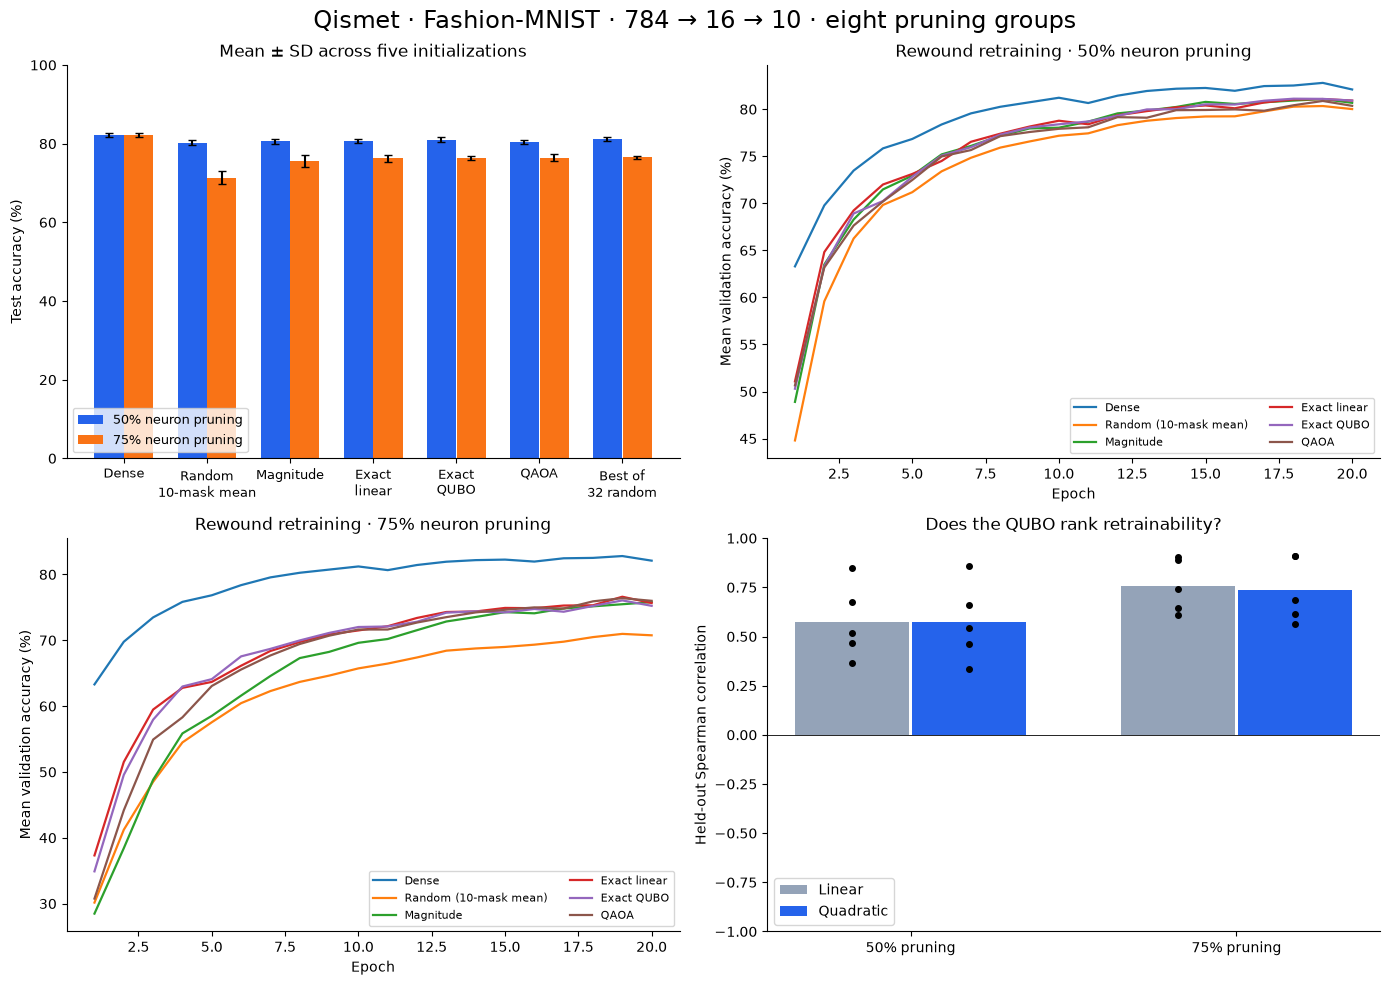

In [7]:
plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
fig,axs=plt.subplots(2,2,figsize=(14,10))
methods=['Dense','Random (10-mask mean)','Magnitude','Exact linear','Exact QUBO','QAOA','Best of 32 random']
xx=np.arange(len(methods))
for offset,pruning,color in [(-.18,50,'#2563eb'),(.18,75,'#f97316')]:
    table=summary[summary.pruning==pruning].set_index('method').loc[methods]
    axs[0,0].bar(xx+offset,table.test_accuracy_mean*100,.35,yerr=table.test_accuracy_sd*100,
                 capsize=3,label=f'{pruning}% neuron pruning',color=color)
axs[0,0].set(xticks=xx,xticklabels=['Dense','Random\n10-mask mean','Magnitude','Exact\nlinear','Exact\nQUBO','QAOA','Best of\n32 random'],
              ylabel='Test accuracy (%)',ylim=(0,100),title='Mean ± SD across five initializations')
axs[0,0].tick_params(axis='x',labelsize=9)
axs[0,0].legend(fontsize=9,loc='lower left')
for ax,pruning in [(axs[0,1],50),(axs[1,0],75)]:
    for method in ['Dense','Random (10-mask mean)','Magnitude','Exact linear','Exact QUBO','QAOA']:
        values=curves[(curves.pruning==pruning)&(curves.method==method)].groupby('epoch').val_accuracy.mean()*100
        ax.plot(values.index,values.values,label=method,linewidth=1.6)
    ax.set(xlabel='Epoch',ylabel='Mean validation accuracy (%)',title=f'Rewound retraining · {pruning}% neuron pruning')
    ax.legend(fontsize=8,ncol=2)
for offset,name,color in [(-.18,'Linear','#94a3b8'),(.18,'Quadratic','#2563eb')]:
    vals=audit_summary[audit_summary.model==name].set_index('pruning').loc[[50,75]]
    axs[1,1].bar(np.arange(2)+offset,vals.spearman_mean,.35,label=name,color=color)
    for index,pruning in enumerate([50,75]):
        point=audit[(audit.model==name)&(audit.pruning==pruning)].spearman
        axs[1,1].scatter(np.full(len(point),index+offset),point,color='black',s=16,zorder=3)
axs[1,1].set(xticks=[0,1],xticklabels=['50% pruning','75% pruning'],ylim=(-1,1),
              ylabel='Held-out Spearman correlation',title='Does the QUBO rank retrainability?')
axs[1,1].axhline(0,color='black',linewidth=.6)
axs[1,1].legend()
fig.suptitle('Qismet · Fashion-MNIST · 784 → 16 → 10 · eight pruning groups',fontsize=17)
fig.tight_layout()
fig.savefig(BASE/'fashion_results.png',dpi=160,bbox_inches='tight')
plt.show()


## Result interpretation

The next cell writes a summary directly from the executed artifacts. Read final accuracy,
paired differences, surrogate prediction/selection quality and QAOA diagnostics together.
The surrogate-label cost is substantial: 177 rewound retrainings per initialization, or 885
label retrainings across five initializations, plus dense/final evaluations. Since there are
only 70 four-group masks and 28 two-group masks, classical enumeration is practical here.
The experiment assesses the formulation and solver behavior, not computational advantage.


In [8]:
def markdown_table(frame):
    cols=list(frame.columns)
    text='| '+' | '.join(cols)+' |\n| '+' | '.join(['---']*len(cols))+' |\n'
    return text+'\n'.join('| '+' | '.join(str(v) for v in row)+' |' for row in frame.itertuples(index=False,name=None))

display_table=summary[['pruning','method','test_accuracy_mean','test_accuracy_sd','parameters']].copy()
display_table['test_accuracy_mean']=(display_table.test_accuracy_mean*100).round(2)
display_table['test_accuracy_sd']=(display_table.test_accuracy_sd*100).round(2)
display_table=display_table.rename(columns={'test_accuracy_mean':'test accuracy (%)','test_accuracy_sd':'SD (pp)'})
report='# Fashion-MNIST executed results\n\n'
report+='784 pixel inputs → 16 ReLU hidden neurons → 10 clothing classes. Fixed groups of two neurons; 8 QAOA qubits.\n\n'
report+='5,000 training / 1,000 validation / 10,000 official test examples; five initialization seeds; 20 epochs per model.\n\n'
report+='## Observed comparison\n\n'
for pruning in [50,75]:
    row=summary[summary.pruning==pruning].set_index('method')
    report+=f"At {pruning}% neuron pruning, mean test accuracy was {row.loc['QAOA','test_accuracy_mean']:.2%} for QAOA, {row.loc['Random (10-mask mean)','test_accuracy_mean']:.2%} for the ten-mask random mean, {row.loc['Exact QUBO','test_accuracy_mean']:.2%} for exact QUBO, {row.loc['Exact linear','test_accuracy_mean']:.2%} for exact linear, and {row.loc['Best of 32 random','test_accuracy_mean']:.2%} for best-of-32 random selection by QUBO cost.\n\n"
report+='The comparison with random pruning tests useful mask selection; comparison with exact linear and best-of-random is needed before attributing any gain to pairwise terms or QAOA.\n\n'
report+='## Final test accuracy\n\n'+markdown_table(display_table)+'\n\n'
report+='## Paired differences: seed-level descriptive 95% t intervals\n\n'+markdown_table(paired.round(3))+'\n\n'
report+='## Surrogate holdout quality and audit-only selection\n\n'+markdown_table(audit_summary.round(4))+'\n\n'
report+='## QAOA optimization and sampling\n\n'+markdown_table(qaoa_summary.round(5))+'\n\n'
report+='The random baseline is a ten-mask average within each seed. The five initialization seeds, not individual masks or epochs, are the replication units. Intervals describe this fixed split and are not a claim of superiority or generalization across datasets.\n\n'
report+='Both surrogate models use the same fitting labels and CV splits. The test set does not guide masks, regression, or optimization. Exact QUBO is an oracle for predicted loss, not actual retraining performance. QAOA uses noiseless classical statevector simulation and 32 final shots. These results do not establish quantum advantage.\n\n'
report+='References: [Fashion-MNIST official repository](https://github.com/zalandoresearch/fashion-mnist); [Lottery Ticket Hypothesis](https://arxiv.org/abs/1803.03635).\n'
(BASE/'RESULTS.md').write_text(report,encoding='utf-8')
display(Markdown(report))


# Fashion-MNIST executed results

784 pixel inputs → 16 ReLU hidden neurons → 10 clothing classes. Fixed groups of two neurons; 8 QAOA qubits.

5,000 training / 1,000 validation / 10,000 official test examples; five initialization seeds; 20 epochs per model.

## Observed comparison

At 50% neuron pruning, mean test accuracy was 80.41% for QAOA, 80.28% for the ten-mask random mean, 80.98% for exact QUBO, 80.73% for exact linear, and 81.11% for best-of-32 random selection by QUBO cost.

At 75% neuron pruning, mean test accuracy was 76.43% for QAOA, 71.34% for the ten-mask random mean, 76.28% for exact QUBO, 76.25% for exact linear, and 76.53% for best-of-32 random selection by QUBO cost.

The comparison with random pruning tests useful mask selection; comparison with exact linear and best-of-random is needed before attributing any gain to pairwise terms or QAOA.

## Final test accuracy

| pruning | method | test accuracy (%) | SD (pp) | parameters |
| --- | --- | --- | --- | --- |
| 50.0 | Dense | 82.18 | 0.47 | 12730.0 |
| 50.0 | Random (10-mask mean) | 80.28 | 0.73 | 6370.0 |
| 50.0 | Magnitude | 80.65 | 0.63 | 6370.0 |
| 50.0 | Exact linear | 80.73 | 0.47 | 6370.0 |
| 50.0 | Exact QUBO | 80.98 | 0.66 | 6370.0 |
| 50.0 | QAOA | 80.41 | 0.55 | 6370.0 |
| 50.0 | Best of 32 random | 81.11 | 0.49 | 6370.0 |
| 75.0 | Dense | 82.18 | 0.47 | 12730.0 |
| 75.0 | Random (10-mask mean) | 71.34 | 1.62 | 3190.0 |
| 75.0 | Magnitude | 75.59 | 1.55 | 3190.0 |
| 75.0 | Exact linear | 76.25 | 0.83 | 3190.0 |
| 75.0 | Exact QUBO | 76.28 | 0.5 | 3190.0 |
| 75.0 | QAOA | 76.43 | 0.9 | 3190.0 |
| 75.0 | Best of 32 random | 76.53 | 0.46 | 3190.0 |

## Paired differences: seed-level descriptive 95% t intervals

| pruning | difference | n_pairs | mean_pp | lower_95_pp | upper_95_pp |
| --- | --- | --- | --- | --- | --- |
| 50.0 | QAOA minus Random (10-mask mean) | 5 | 0.128 | -0.362 | 0.618 |
| 50.0 | QAOA minus Exact QUBO | 5 | -0.572 | -1.782 | 0.638 |
| 50.0 | QAOA minus Magnitude | 5 | -0.242 | -0.472 | -0.012 |
| 50.0 | Exact QUBO minus Exact linear | 5 | 0.246 | -0.675 | 1.167 |
| 50.0 | Exact QUBO minus Random (10-mask mean) | 5 | 0.7 | -0.599 | 2.0 |
| 50.0 | QAOA minus Dense | 5 | -1.768 | -2.566 | -0.97 |
| 75.0 | QAOA minus Random (10-mask mean) | 5 | 5.09 | 3.346 | 6.834 |
| 75.0 | QAOA minus Exact QUBO | 5 | 0.152 | -1.278 | 1.582 |
| 75.0 | QAOA minus Magnitude | 5 | 0.836 | -1.03 | 2.702 |
| 75.0 | Exact QUBO minus Exact linear | 5 | 0.026 | -1.447 | 1.499 |
| 75.0 | Exact QUBO minus Random (10-mask mean) | 5 | 4.938 | 2.339 | 7.537 |
| 75.0 | QAOA minus Dense | 5 | -5.748 | -7.059 | -4.437 |

## Surrogate holdout quality and audit-only selection

| pruning | model | mae_mean | r2_mean | spearman_mean | selection_regret_mean | selected_val_loss_mean | audit_masks_per_seed |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 50.0 | Linear | 0.0512 | -7.0262 | 0.5745 | 0.0121 | 0.5538 | 35 |
| 50.0 | Quadratic | 0.0357 | -3.4653 | 0.5718 | 0.0189 | 0.5606 | 35 |
| 75.0 | Linear | 0.0882 | 0.1663 | 0.7574 | 0.0221 | 0.6663 | 14 |
| 75.0 | Quadratic | 0.1144 | -0.7416 | 0.7363 | 0.0116 | 0.6558 | 14 |

## QAOA optimization and sampling

| pruning | exact_hits | trials | mean_surrogate_gap | mean_feasible_probability | mean_top_decile_conditional | uniform_top_decile | mean_feasible_shots |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 50.0 | 1 | 5 | 0.01175 | 0.76757 | 0.10008 | 0.1 | 24.8 |
| 75.0 | 2 | 5 | 0.00939 | 0.52988 | 0.10789 | 0.10714 | 17.8 |

The random baseline is a ten-mask average within each seed. The five initialization seeds, not individual masks or epochs, are the replication units. Intervals describe this fixed split and are not a claim of superiority or generalization across datasets.

Both surrogate models use the same fitting labels and CV splits. The test set does not guide masks, regression, or optimization. Exact QUBO is an oracle for predicted loss, not actual retraining performance. QAOA uses noiseless classical statevector simulation and 32 final shots. These results do not establish quantum advantage.

References: [Fashion-MNIST official repository](https://github.com/zalandoresearch/fashion-mnist); [Lottery Ticket Hypothesis](https://arxiv.org/abs/1803.03635).


## Sources and saved evidence

- [Fashion-MNIST official repository and dataset](https://github.com/zalandoresearch/fashion-mnist).
- [Frankle and Carbin: The Lottery Ticket Hypothesis](https://arxiv.org/abs/1803.03635).
- [IBM Qiskit QAOA tutorial](https://quantum.cloud.ibm.com/docs/en/tutorials/quantum-approximate-optimization-algorithm).

`environment.json` records the execution environment. `dataset_subset.npz` contains the actual image arrays, class labels and official-training-set
indices. `protocol.json` records settings. Each `results/seed_*/` folder contains fitting/audit
labels, all label learning curves, initialization and selected-network checkpoints, surrogate
coefficients, selections, QAOA samples/traces, and completion records. Aggregated CSVs and
this notebook expose the calculations rather than relying on a narrative conclusion.
